In [53]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

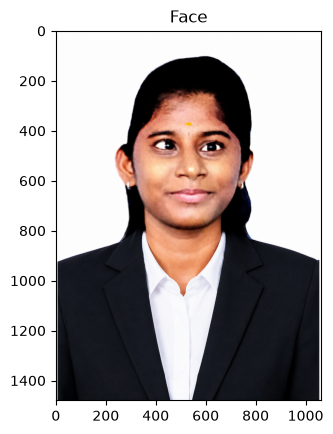

In [54]:
# Load the Face Image
faceImage = cv2.imread('Image.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [55]:
faceImage.shape

(1480, 1063, 3)

In [56]:
#resized_faceImage.shape
faceImage.shape

(1480, 1063, 3)

Text(0.5, 1.0, 'glassPNG')

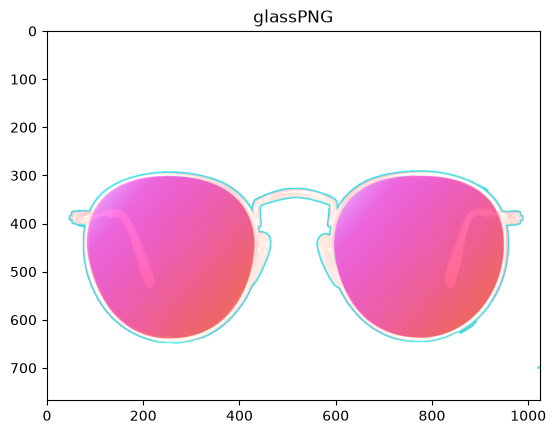

In [57]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass-png-trendy-sunglasses-prescription-sunglasses-1024.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [58]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(360,140))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(140, 360, 4)


In [59]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

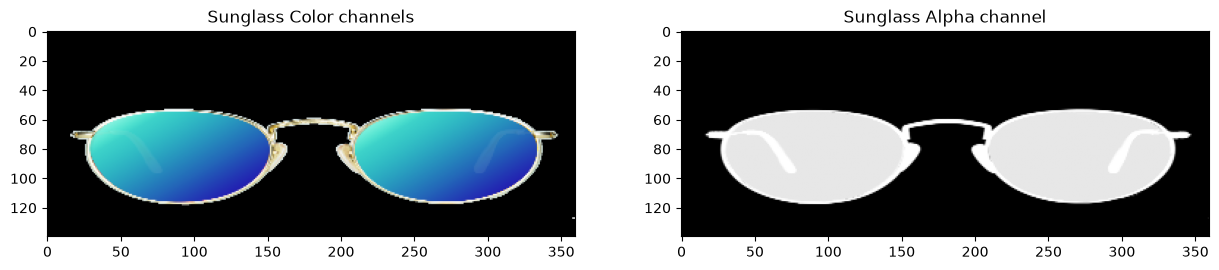

In [60]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

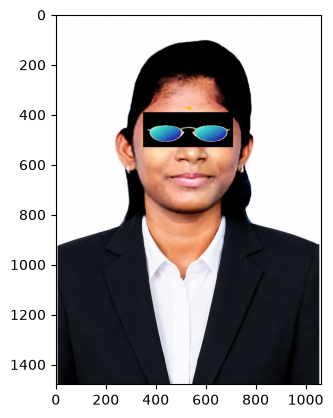

In [61]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Resize sunglasses
glassBGR = cv2.resize(glassBGR, (360, 140))

# Replace the eye region with the sunglass image
faceWithGlassesNaive[390:530, 350:710] = glassBGR

plt.imshow(faceWithGlassesNaive[..., ::-1])
plt.show()

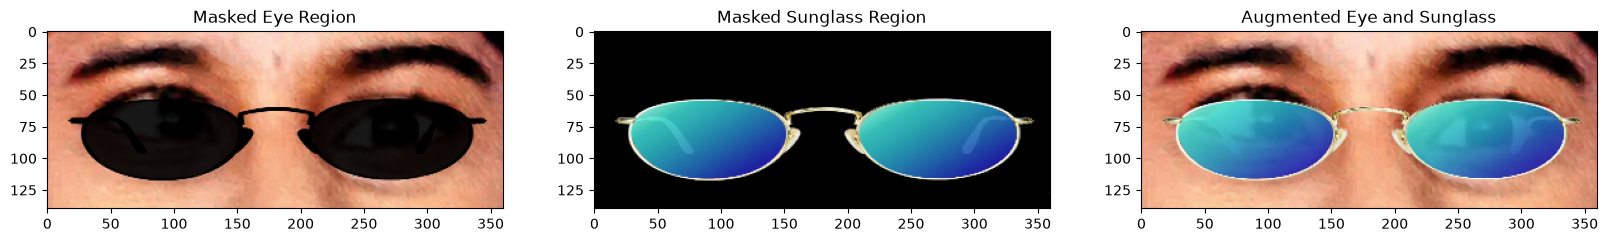

In [67]:
# Resize original sunglasses image
glassPNG = cv2.resize(glassPNG, (360, 140))

# Extract BGR and Alpha channel
glassBGR = glassPNG[:, :, :3]
glassMask1 = glassPNG[:, :, 3]

# Create 3-channel mask
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Normalize mask
glassMask = glassMask.astype(np.float32) / 255.0

# Convert sunglasses to float32
glassBGR = glassBGR.astype(np.float32)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get eye region
eyeROI = faceWithGlassesArithmetic[390:530, 350:710]
eyeROI = eyeROI.astype(np.float32)

# Masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Masked sunglass region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display intermediate results
plt.figure(figsize=[20,20])

plt.subplot(131)
plt.imshow(np.uint8(np.clip(maskedEye, 0, 255))[...,::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(np.uint8(np.clip(maskedGlass, 0, 255))[...,::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(np.uint8(np.clip(eyeRoiFinal, 0, 255))[...,::-1])
plt.title("Augmented Eye and Sunglass")

plt.show()

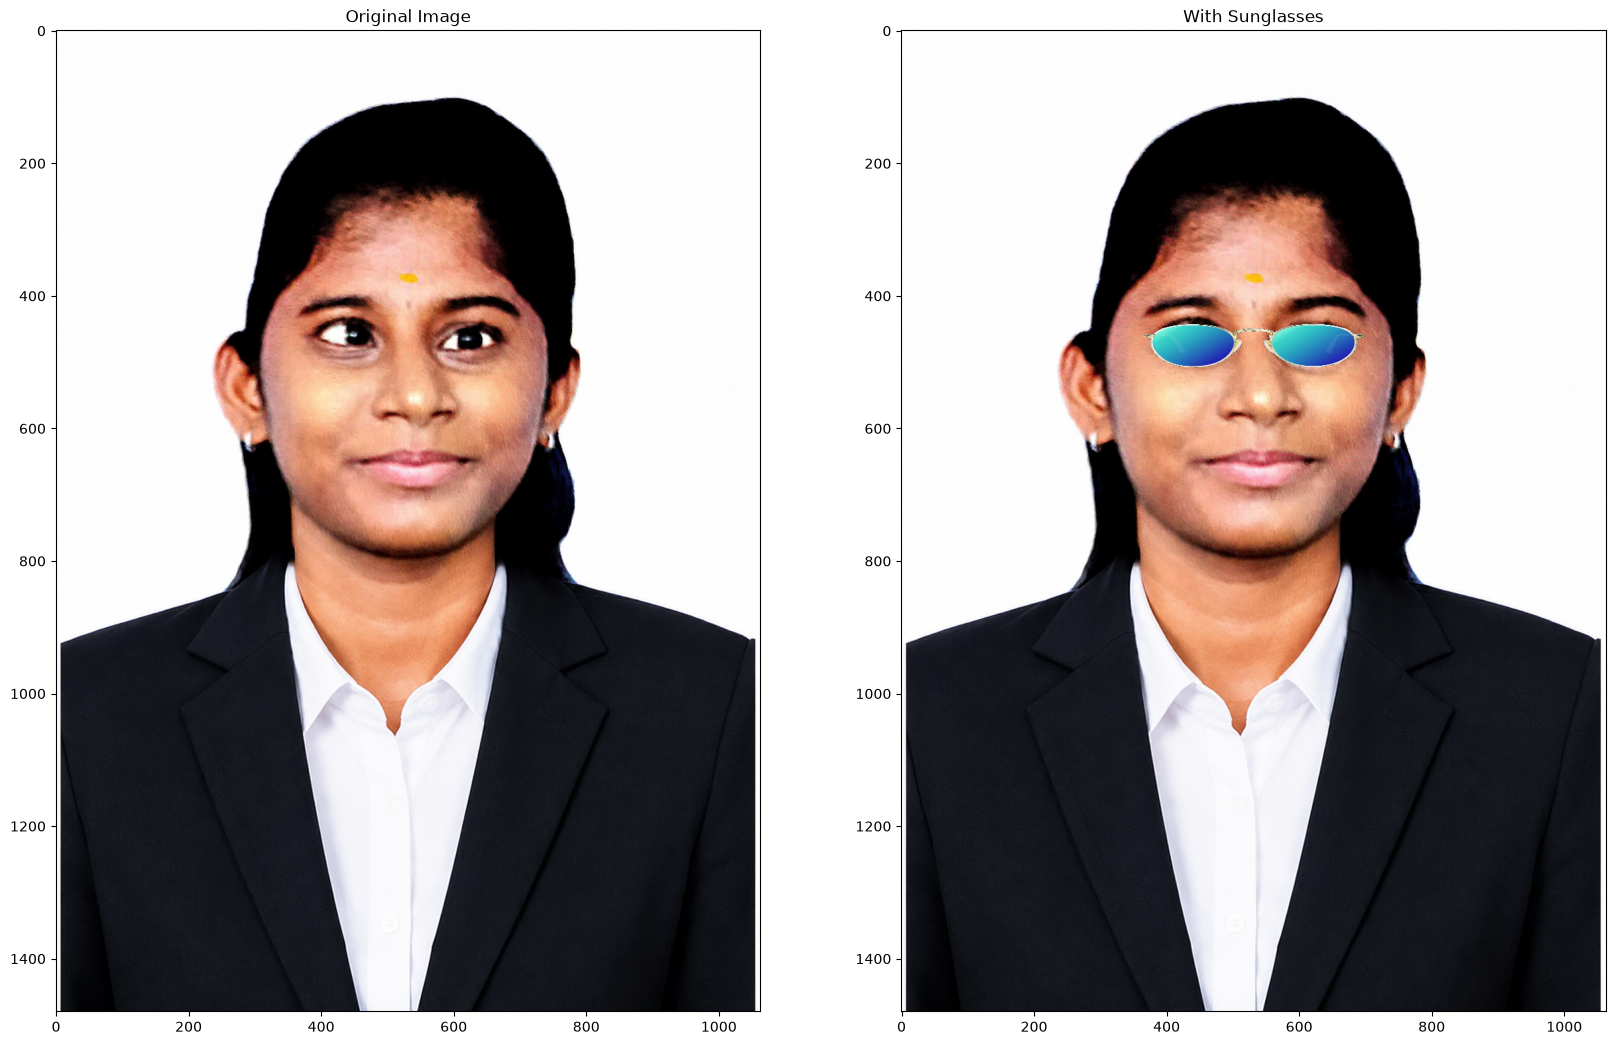

In [63]:
# Resize sunglasses
glassBGR = cv2.resize(glassBGR, (360, 140))

# Create mask from sunglasses image
grayGlass = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
_, glassMask1 = cv2.threshold(grayGlass, 10, 255, cv2.THRESH_BINARY)

# Convert mask into 3 channels
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Normalize mask
glassMask = glassMask.astype(np.float32) / 255.0

# Convert sunglasses to float32
glassBGR = glassBGR.astype(np.float32)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region
eyeROI = faceWithGlassesArithmetic[390:530, 350:710]
eyeROI = eyeROI.astype(np.float32)

# Masked eye region
maskedEye = cv2.multiply(eyeROI, (1 - glassMask))

# Masked sunglasses region
maskedGlass = cv2.multiply(glassBGR, glassMask)

# Combine both images
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Replace eye region
faceWithGlassesArithmetic[390:530, 350:710] = np.uint8(eyeRoiFinal)

# Display final result
plt.figure(figsize=[20,20])
plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:,:,::-1])
plt.title("With Sunglasses")

plt.show()